<a href="https://colab.research.google.com/github/SJ174/MLCW/blob/main/MLCW_Task_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


##Data Cleaning

In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (7043, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 

In [4]:
#Converts TotalCharges into a numerical column
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].str.strip(),
    errors='coerce'
)
print("TotalCharges data type:", df['TotalCharges'].dtype)

print("\nMissing TotalCharges:", df['TotalCharges'].isnull().sum())

TotalCharges data type: float64

Missing TotalCharges: 11


In [5]:
#Replacing missing TotalCharges values with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Remaining missing values:")
print(df.isnull().sum())

print("\nTotalCharges data type:")
print(df['TotalCharges'].dtype)

Remaining missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

TotalCharges data type:
float64


The data cleaning process involved converting the TotalCharges column from an object data type into a numerical format using pandas. During this process, 11 empty string values were identified and converted into missing values (NaN).

Further investigation during the EDA revealed that all 11 affected customers had a tenure of zero months. Therefore, the missing TotalCharges values were replaced with zero, as these customers had no accumulated service charges recorded.

No duplicate records were identified during the inspection.


##Dataset Splitting

In [6]:
#Removes customerID from input features
X = df.drop(columns=['customerID', 'Churn'])
#Seperates target variable
y = df['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)

Training target distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


##Categorical Encoding

In [8]:
numerical_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]
categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]
print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 3
Number of categorical features: 16


In [9]:
#Preprocessing for KNN and Logistic Regression
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)
# Preprocessing for Random Forest
unscaled_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)
print("Preprocessing transformers created successfully.")

Preprocessing transformers created successfully.


In [10]:
#Encodes target variable by converting it to binary values
y_train = y_train.map({'No': 0, 'Yes': 1})
y_test = y_test.map({'No': 0, 'Yes': 1})

print("Training target values:")
print(y_train.value_counts())

print("\nTesting target values:")
print(y_test.value_counts())

Training target values:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target values:
Churn
0    1035
1     374
Name: count, dtype: int64


###Data Preprocessing Summary

The dataset was prepared for machine learning by separating the input features from the target variable. The customerID column was excluded as it serves only as a unique identifier and does not provide meaningful predictive information.

The dataset was divided into training (80%) and testing (20%) subsets using stratified sampling to maintain the original churn class distribution.

Numerical and categorical features were identified separately. One-Hot Encoding was selected to convert categorical variables into numerical representations, while StandardScaler was selected to standardise numerical features for algorithms sensitive to feature magnitudes.

Separate preprocessing transformers were created for scaled and unscaled numerical data. Scaling will be applied to KNN and Logistic Regression, while Random Forest will use the original numerical feature values.

Finally, the target variable was converted into binary values, with 'No' represented by 0 and 'Yes' represented by 1.


##KNN Classification

In [11]:
knn_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('classifier', KNeighborsClassifier())
])
print("KNN pipeline created successfully.")

KNN pipeline created successfully.


In [12]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

#Sets up 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
print("5-fold stratified cross-validation configured.")

5-fold stratified cross-validation configured.


In [13]:
knn_param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}
print("Number of hyperparameter combinations:",
      10 * 2 * 2)

Number of hyperparameter combinations: 40


In [14]:
knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
knn_grid_search.fit(X_train, y_train)
print("\nKNN Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 40 candidates, totalling 200 fits

KNN Hyperparameter Tuning Completed!


In [15]:
print("Best KNN Parameters:")
print(knn_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(knn_grid_search.best_score_, 4))

Best KNN Parameters:
{'classifier__metric': 'euclidean', 'classifier__n_neighbors': 17, 'classifier__weights': 'uniform'}

Best Cross-Validation F1-Score:
0.5932


In [16]:
knn_results = pd.DataFrame(knn_grid_search.cv_results_)

knn_results = knn_results[
    [
        'param_classifier__n_neighbors',
        'param_classifier__weights',
        'param_classifier__metric',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]
knn_results.columns = [
    'K',
    'Weights',
    'Distance Metric',
    'Mean CV F1-Score',
    'Standard Deviation',
    'Rank'
]
knn_results = knn_results.sort_values('Rank')
knn_results.round(4)

,K,Weights,Distance Metric,Mean CV F1-Score,Standard Deviation,Rank
14,17,uniform,euclidean,0.5932,0.0132,1
38,21,uniform,manhattan,0.5926,0.0197,2
18,21,uniform,euclidean,0.5909,0.0201,3
16,19,uniform,euclidean,0.5892,0.0161,4
36,19,uniform,manhattan,0.5890,0.0169,5
12,15,uniform,euclidean,0.5845,0.0138,6
32,15,uniform,manhattan,0.5843,0.0138,7
34,17,uniform,manhattan,0.5822,0.0115,8
10,13,uniform,euclidean,0.5821,0.0174,9
30,13,uniform,manhattan,0.5777,0.0151,10


###KNN Hyperparameter Tuning Results
Hyperparameter tuning was performed using GridSearchCV with five-fold stratified cross-validation. A total of 40 hyperparameter combinations were evaluated by varying the number of neighbours, distance weighting method and distance metric.

The best-performing configuration used 17 neighbours, uniform weighting and the Euclidean distance metric, achieving a mean cross-validation F1-score of 0.5932 with a standard deviation of 0.0132.


In [17]:
#Uses the best KNN model
best_knn = knn_grid_search.best_estimator_

y_pred_knn = best_knn.predict(X_test)

y_prob_knn = best_knn.predict_proba(X_test)[:, 1]

print("KNN test predictions generated successfully.")

KNN test predictions generated successfully.


In [18]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)
knn_auc = roc_auc_score(y_test, y_prob_knn)

print("KNN Test Performance")
print("-------------------------")
print("Accuracy:", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1-Score:", round(knn_f1, 4))
print("ROC-AUC:", round(knn_auc, 4))

KNN Test Performance
-------------------------
Accuracy: 0.7786
Precision: 0.5871
Recall: 0.5588
F1-Score: 0.5726
ROC-AUC: 0.8226


In [19]:
print("KNN Classification Report")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=['No Churn', 'Churn']
))

KNN Classification Report
              precision    recall  f1-score   support

    No Churn       0.84      0.86      0.85      1035
       Churn       0.59      0.56      0.57       374

    accuracy                           0.78      1409
   macro avg       0.72      0.71      0.71      1409
weighted avg       0.78      0.78      0.78      1409



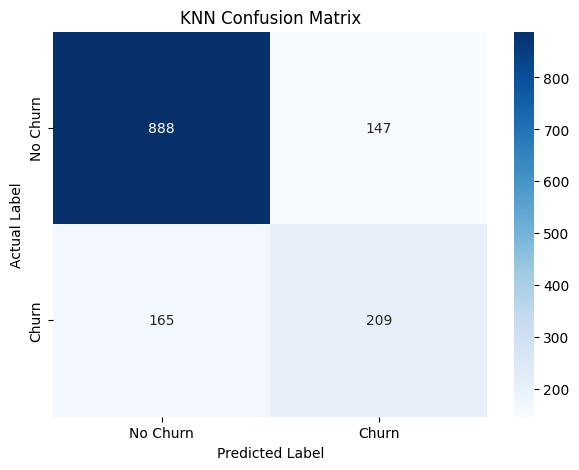

In [20]:
knn_cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(7, 5))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

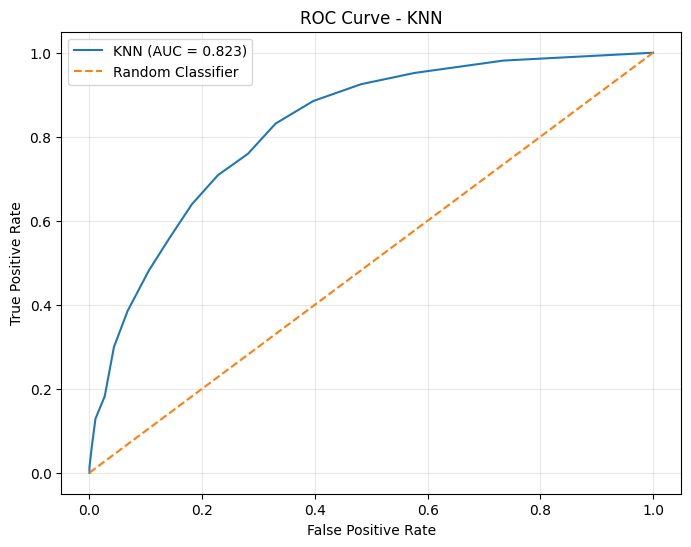

In [21]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_knn)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'KNN (AUC = {knn_auc:.3f})'
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)
plt.title('ROC Curve - KNN')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [22]:
from sklearn.model_selection import cross_validate

knn_cv_results = cross_validate(
    best_knn,
    X_train,
    y_train,
    cv=cv,
    scoring='f1',
    return_train_score=True,
    n_jobs=-1
)
knn_train_f1 = knn_cv_results['train_score'].mean()
knn_validation_f1 = knn_cv_results['test_score'].mean()

print("KNN Overfitting Analysis")
print("-----------------------------")
print("Mean Training F1-Score:",
      round(knn_train_f1, 4))

print("Mean Validation F1-Score:",
      round(knn_validation_f1, 4))

print("Training-Validation Gap:",
      round(knn_train_f1 - knn_validation_f1, 4))

print("\nIndividual Fold Results:")
print(pd.DataFrame({
    'Training F1': knn_cv_results['train_score'],
    'Validation F1': knn_cv_results['test_score']
}).round(4))

KNN Overfitting Analysis
-----------------------------
Mean Training F1-Score: 0.6317
Mean Validation F1-Score: 0.5932
Training-Validation Gap: 0.0384

Individual Fold Results:
   Training F1  Validation F1
0       0.6242         0.5954
1       0.6397         0.5685
2       0.6277         0.6014
3       0.6333         0.6071
4       0.6334         0.5936


In [23]:
#Stores KNN results
knn_summary = {
    'Model': 'KNN',
    'Best Parameters': knn_grid_search.best_params_,
    'CV F1-Score': knn_grid_search.best_score_,
    'Test Accuracy': knn_accuracy,
    'Test Precision': knn_precision,
    'Test Recall': knn_recall,
    'Test F1-Score': knn_f1,
    'Test ROC-AUC': knn_auc,
    'Training F1-Score': knn_train_f1,
    'Validation F1-Score': knn_validation_f1
}
print("KNN results saved successfully.")

KNN results saved successfully.


###KNN Model Results and Discussion

#### Test Dataset Evaluation

The selected KNN model was evaluated using the previously reserved test dataset containing 1,409 customer records. The model achieved an accuracy of 77.86%, precision of 58.71%, recall of 55.88%, F1-score of 57.26% and ROC-AUC of 0.8226.

The accuracy indicates that the model correctly classified approximately 78% of the test records. However, its precision and recall for the churn class were comparatively lower, indicating that the model has some difficulty reliably identifying customers who are likely to leave.

The ROC-AUC score of 0.8226 indicates that the model has good discriminatory ability when distinguishing between customers who churn and those who remain.

#### Confusion Matrix Analysis

The confusion matrix showed that the model correctly identified 888 customers who did not churn and 209 customers who churned. However, it incorrectly classified 147 non-churning customers as churners and failed to identify 165 customers who actually churned.

This indicates that although the model performs reasonably well at identifying customers who remain with the company, it misses a considerable proportion of actual churners. Improving churn detection remains an important area for potential improvement.

#### Overfitting and Underfitting Analysis

The overfitting and underfitting analysis was conducted using five-fold stratified cross-validation. The model achieved a mean training F1-score of 0.6317 and a mean validation F1-score of 0.5932, resulting in a relatively small training-validation gap of approximately 0.0384.

The relatively small difference between training and validation performance suggests that the model generalises reasonably consistently to unseen data, with no strong indication of severe overfitting.

The individual fold results also demonstrated relatively consistent validation performance. Furthermore, the test F1-score of 0.5726 was reasonably close to the cross-validation F1-score, providing additional evidence of consistent generalisation performance.

#### Overall Discussion

Overall, the KNN classifier demonstrated moderate predictive performance, achieving a test accuracy of 77.86% and an F1-score of 57.26%. Although the model achieved a relatively strong ROC-AUC score, its ability to identify customers who actually churned was more limited, as reflected by its recall of 55.88%.

The results suggest that KNN can distinguish between customers with different churn outcomes to a reasonable extent, but its classification performance could be improved, particularly in identifying customers who are likely to leave. These findings will be considered when comparing KNN with Logistic Regression and Random Forest.
